3rd harmonic tuning frequency: 177.00018735306102 Hz
5th harmonic tuning frequency: 294.0010468442598 Hz


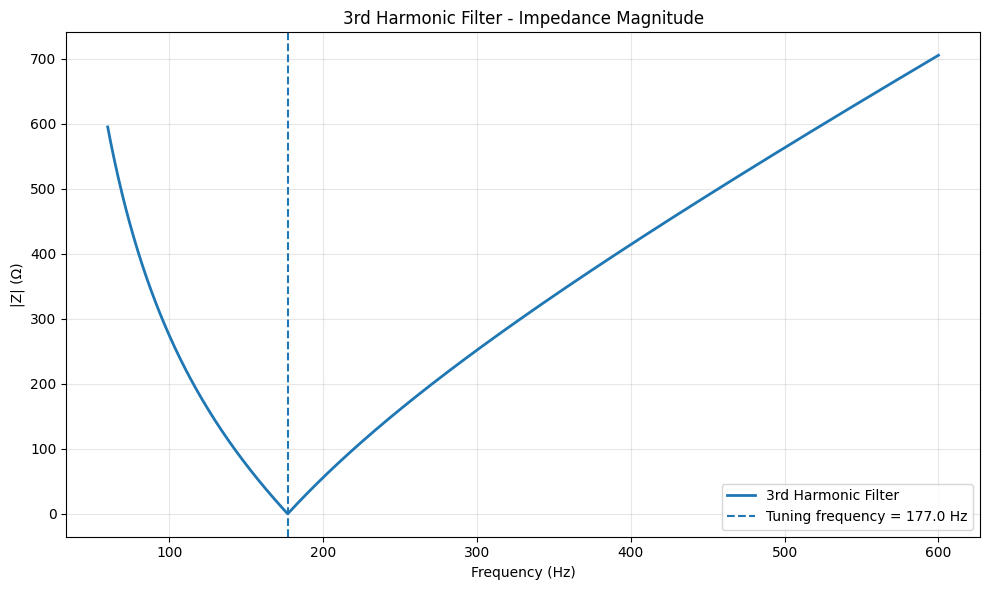

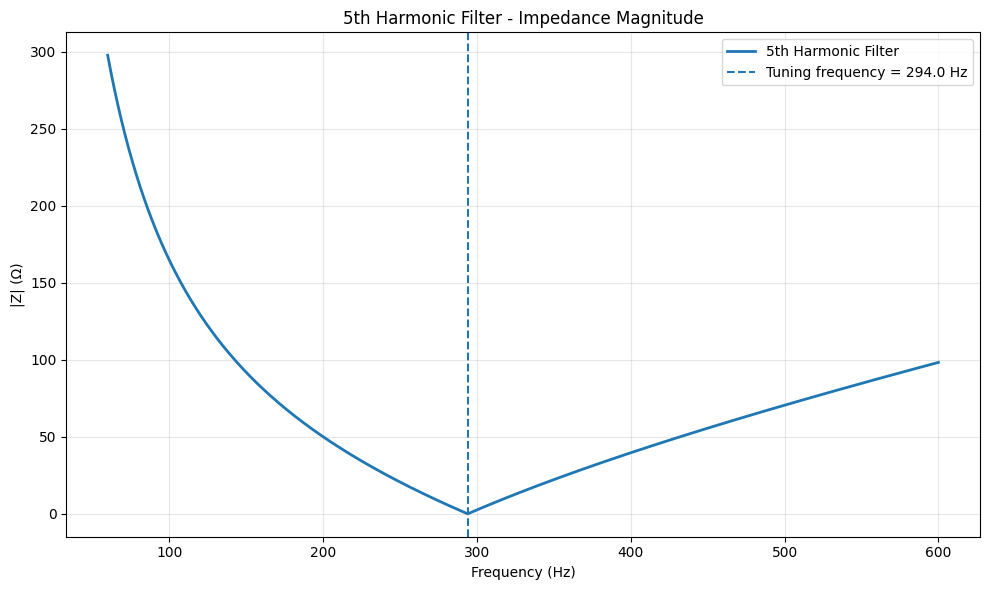

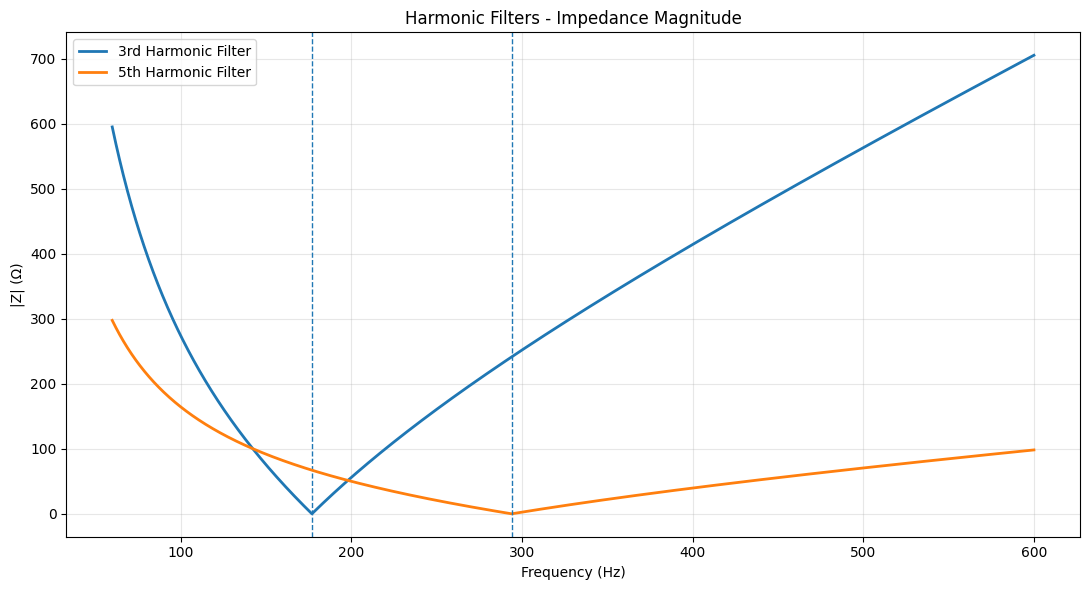

In [3]:
import numpy as np
import matplotlib.pyplot as plt


class HarmonicFilter:
    """
    Harmonic filter impedance model.

    Tuned filter:
        r -- L -- C

    Damped filter:
        r -- (L || R) -- C
    """

    def __init__(self, L, C, r=0.0, R=np.inf, name="Harmonic Filter"):
        self.L = float(L)
        self.C = float(C)
        self.r = 0.0 if r is None else float(r)
        self.R = np.inf if R is None else float(R)
        self.name = name

    @property
    def tuning_frequency(self):
        """
        Return the ideal LC tuning frequency in Hz.
        """
        return 1 / (2 * np.pi * np.sqrt(self.L * self.C))

    def impedance(self, frequency):
        """
        Return the filter impedance.
        """

        frequency = np.asarray(frequency, dtype=float)

        omega = 2 * np.pi * frequency

        ZL = 1j * omega * self.L
        ZC = 1 / (1j * omega * self.C)

        if np.isinf(self.R):
            Z_branch = ZL
        else:
            Z_branch = (ZL * self.R) / (ZL + self.R)

        Z = self.r + Z_branch + ZC

        return Z

    def impedance_magnitude(self, frequency):
        """
        Return the impedance magnitude.
        """
        return np.abs(self.impedance(frequency))

    def plot(self, f_min=60, f_max=600, points=2000):
        """
        Plot impedance magnitude versus frequency.
        """

        frequency = np.linspace(
            f_min,
            f_max,
            points
        )

        Z = self.impedance_magnitude(frequency)

        fig, ax = plt.subplots(
            figsize=(10, 6)
        )

        ax.plot(
            frequency,
            Z,
            linewidth=2,
            label=self.name
        )

        ax.axvline(
            self.tuning_frequency,
            linestyle="--",
            linewidth=1.5,
            label=f"Tuning frequency = {self.tuning_frequency:.1f} Hz"
        )

        ax.set_xlabel(
            "Frequency (Hz)"
        )

        ax.set_ylabel(
            "|Z| (Ω)"
        )

        ax.set_title(
            f"{self.name} - Impedance Magnitude"
        )

        ax.grid(
            True,
            alpha=0.3
        )

        ax.legend()

        plt.tight_layout()
        plt.show()


def plot_filters(filters, f_min=60, f_max=600, points=2000):
    """
    Plot multiple harmonic filters.
    """

    frequency = np.linspace(
        f_min,
        f_max,
        points
    )

    fig, ax = plt.subplots(
        figsize=(11, 6)
    )

    for harmonic_filter in filters:

        Z = harmonic_filter.impedance_magnitude(
            frequency
        )

        ax.plot(
            frequency,
            Z,
            linewidth=2,
            label=harmonic_filter.name
        )

        ax.axvline(
            harmonic_filter.tuning_frequency,
            linestyle="--",
            linewidth=1
        )

    ax.set_xlabel(
        "Frequency (Hz)"
    )

    ax.set_ylabel(
        "|Z| (Ω)"
    )

    ax.set_title(
        "Harmonic Filters - Impedance Magnitude"
    )

    ax.grid(
        True,
        alpha=0.3
    )

    ax.legend()

    plt.tight_layout()
    plt.show()


# =============================================================================
# Third harmonic filter
# =============================================================================

filter_3rd = HarmonicFilter(
    L=204.949e-3,
    C=3.945e-6,
    name="3rd Harmonic Filter"
)


# =============================================================================
# Fifth harmonic filter
# =============================================================================

filter_5th = HarmonicFilter(
    L=34.303e-3,
    C=8.543e-6,
    name="5th Harmonic Filter"
)


# =============================================================================
# Results
# =============================================================================

print(
    "3rd harmonic tuning frequency:",
    filter_3rd.tuning_frequency,
    "Hz"
)

print(
    "5th harmonic tuning frequency:",
    filter_5th.tuning_frequency,
    "Hz"
)


# =============================================================================
# Individual plots
# =============================================================================

filter_3rd.plot()

filter_5th.plot()


# =============================================================================
# Combined plot
# =============================================================================

plot_filters([
    filter_3rd,
    filter_5th
])